In [1]:
# !find .venv -name "*.so*" | grep nvidia | xargs dirname | sort -u | paste -d ":" -s -
# !export LD_LIBRARY_PATH=$(find .venv -name "*.so*" | grep nvidia | xargs dirname | sort -u | paste -d ":" -s -) 
# !export LD_LIBRARY_PATH=$LD_LIBRARY_PATH:$(find .venv -name "*.so*" | grep nvidia | xargs dirname | sort -u | sed 's/^/\/home\/hunterx\//' | paste -d ":" -s - )
!python3 -c "import tensorflow as tf; print(tf.config.list_physical_devices('GPU'))"

I0000 00:00:1781875575.535254   40254 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781875575.806549   40254 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781875577.785117   40254 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1781875580.708965   40254 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute c

# Downloading the dataset
We are downloading the dataset from Hugging Face using the `datasets` library.

In [2]:
from datasets import load_dataset

ds = load_dataset("mapo80/DocCornerDataset")

/home/hunterx/DocumentCorNet/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Visualizing the dataset
We are visualizing the dataset using the `matplotlib` library. We are visualizing multiple random samples from the dataset.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random

def visualize_multiple_random_samples(dataset, split='train', num_samples=9):
    samples = dataset[split]
    
    fig, axes = plt.subplots(3, 3, figsize=(24, 16))
    axes = axes.flatten()
    
    for i in range(num_samples):
        # Pick a random index, ensuring we pick an image that ACTUALLY contains a document (is_negative == False)
        while True:
            idx = random.randint(0, len(samples) - 1)
            sample = samples[idx]
            if not sample['is_negative']:
                break
                
        image = sample['image']
        width, height = image.size
        ax = axes[i]
        
        ax.imshow(image)
        
        # The coordinates in the dataset are normalized between 0 and 1!
        # They need to be multiplied by width and height to map to the image's pixel dimensions.
        corners_x = [
            sample['corner_tl_x'] * width, 
            sample['corner_tr_x'] * width, 
            sample['corner_br_x'] * width, 
            sample['corner_bl_x'] * width, 
            sample['corner_tl_x'] * width
        ]
        corners_y = [
            sample['corner_tl_y'] * height, 
            sample['corner_tr_y'] * height, 
            sample['corner_br_y'] * height, 
            sample['corner_bl_y'] * height, 
            sample['corner_tl_y'] * height
        ]
        
        # Plot the exact four corners
        ax.plot(corners_x, corners_y, color='green', linestyle='-', linewidth=3, label='Document Corners' if i == 0 else '', zorder=2)
        ax.scatter(corners_x[:-1], corners_y[:-1], c='green', edgecolors='green', s=80, zorder=3, label='Corner Points' if i == 0 else '')
        
        ax.set_title(f"{sample['filename']}\n(Index: {idx})")
        ax.axis('off')
        
    # Add a single legend to the figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize='large')
    
    plt.tight_layout(rect=[0, 0.05, 1, 1]) # Leave space for the legend
    plt.show()

# Visualize 6 random positive samples from the training set
visualize_multiple_random_samples(ds, split='train', num_samples=9)

# Preparing the dataset for training
We are preparing the dataset for training the model. We are creating a TensorFlow dataset from the Hugging Face dataset. We are applying data augmentation and batching the dataset for training.

In [3]:
import tensorflow as tf

IMG_SIZE = 224          # Input image size
HEATMAP_SIZE = 56       # Output heatmap size
GAUSSIAN_SIGMA = 3      # Gaussian sigma for heatmap generation
BATCH_SIZE = 64
TRAIN_LIMIT = None      # None uses full dataset
VAL_LIMIT = None        # None uses full dataset
TEST_LIMIT = None       # None uses full dataset

from datasets import Image as HFImage

# Stop the dataset library from decoding images into PIL objects - we want raw
# bytes so decoding can happen inside TensorFlow's own graph ops instead, where
# it actually runs in parallel across CPU cores via num_parallel_calls.
raw_splits = {
    "train": ds["train"].cast_column("image", HFImage(decode=False)),
    "validation": ds["validation"].cast_column("image", HFImage(decode=False)),
    "test": ds["test"].cast_column("image", HFImage(decode=False)),
}

def load_raw_bytes(split):
    """
    Yields raw image bytes + labels only. No decode, no resize, no heatmap
    math here - this generator just reads dict fields, so its single-thread
    nature doesn't matter. All the expensive work happens in the parallel
    .map() calls below.
    """
    samples = raw_splits[split]
    max_samples = {"train": TRAIN_LIMIT, "validation": VAL_LIMIT, "test": TEST_LIMIT}[split]

    for idx, sample in enumerate(samples):
        if max_samples is not None and idx >= max_samples:
            break

        is_negative = sample.get("is_negative", False)

        img_field = sample["image"]
        img_bytes = img_field["bytes"]
        if img_bytes is None:  # dataset stores a path reference instead of embedded bytes
            with open(img_field["path"], "rb") as f:
                img_bytes = f.read()

        if is_negative:
            corners = [0.0] * 8
        else:
            corners = [
                sample["corner_tl_x"], sample["corner_tl_y"],
                sample["corner_tr_x"], sample["corner_tr_y"],
                sample["corner_br_x"], sample["corner_br_y"],
                sample["corner_bl_x"], sample["corner_bl_y"],
            ]

        yield img_bytes, corners, 0.0 if is_negative else 1.0

raw_output_signature = (
    tf.TensorSpec(shape=(), dtype=tf.string),
    tf.TensorSpec(shape=(8,), dtype=tf.float32),
    tf.TensorSpec(shape=(), dtype=tf.float32),
)

# Coordinate grids for the Gaussian heatmaps, built once as TF constants.
_HM_X = tf.reshape(tf.range(HEATMAP_SIZE, dtype=tf.float32), (1, HEATMAP_SIZE))
_HM_Y = tf.reshape(tf.range(HEATMAP_SIZE, dtype=tf.float32), (HEATMAP_SIZE, 1))

def make_gaussian_heatmap(center_x, center_y, sigma=GAUSSIAN_SIGMA):
    cx = center_x * HEATMAP_SIZE
    cy = center_y * HEATMAP_SIZE
    return tf.exp(-((_HM_X - cx) ** 2 + (_HM_Y - cy) ** 2) / (2 * sigma ** 2))

def decode_and_build_targets(img_bytes, corners, doc_present):
    """Decode + resize + build heatmap targets - pure TF ops, so this runs in
    parallel across CPU cores when used inside .map(num_parallel_calls=...)."""
    image = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0

    heatmaps = tf.stack([
        make_gaussian_heatmap(corners[0], corners[1]),
        make_gaussian_heatmap(corners[2], corners[3]),
        make_gaussian_heatmap(corners[4], corners[5]),
        make_gaussian_heatmap(corners[6], corners[7]),
    ], axis=-1)
    heatmaps = heatmaps * doc_present  # zero out for negative (no-document) samples

    return image, (heatmaps, doc_present)

def augment(image, targets):
    """Photometric jitter as vectorized tf.image ops instead of PIL.ImageEnhance -
    runs in C++, releases the GIL, and parallelizes across CPU threads."""
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, targets

print("Preparing training dataset...")
train_ds = (
    tf.data.Dataset.from_generator(lambda: load_raw_bytes("train"), output_signature=raw_output_signature)
    .shuffle(2048)
    .map(decode_and_build_targets, num_parallel_calls=tf.data.AUTOTUNE)
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .repeat()  # Required when using steps_per_epoch across multiple epochs
    .prefetch(tf.data.AUTOTUNE)
)

print("Preparing validation dataset...")
val_ds = (
    tf.data.Dataset.from_generator(lambda: load_raw_bytes("validation"), output_signature=raw_output_signature)
    .map(decode_and_build_targets, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .repeat()  # Required when using validation_steps across multiple epochs
    .prefetch(tf.data.AUTOTUNE)
)

print("Preparing test dataset...")
test_ds = (
    tf.data.Dataset.from_generator(lambda: load_raw_bytes("test"), output_signature=raw_output_signature)
    .map(decode_and_build_targets, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
print("Datasets ready!")


I0000 00:00:1781875621.101619   40221 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781875621.311753   40221 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781875622.875958   40221 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1781875624.674807   40221 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute c

Preparing training dataset...
Preparing validation dataset...
Preparing test dataset...
Datasets ready!


# Visualizing the dataset after processing

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def find_peak(hm):
    """
    Returns (x, y) location of the maximum value in a heatmap.
    """
    y, x = np.unravel_index(np.argmax(hm), hm.shape)
    return x, y


def show_image_with_combined_heatmap(tf_dataset, num_samples=9):
    """
    Show:
    - Preprocessed image
    - Combined GT heatmap overlay
    - GT corner peak locations
    """

    # Get one batch from the dataset
    for batch_images, (batch_heatmaps, batch_doc_present) in tf_dataset.take(1):
        break

    num_samples = min(num_samples, batch_images.shape[0])

    rows = int(np.ceil(np.sqrt(num_samples)))
    cols = int(np.ceil(num_samples / rows))

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(6 * cols, 6 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for i in range(num_samples):

        image = batch_images[i].numpy()
        heatmaps = batch_heatmaps[i].numpy()
        doc_present = batch_doc_present[i].numpy()

        ax = axes[i]

        # Show image
        ax.imshow(image)

        if doc_present > 0.5:

            # Combine all 4 corner heatmaps
            combined_heatmap = np.max(
                heatmaps,
                axis=-1
            )

            # Overlay heatmap
            ax.imshow(
                combined_heatmap,
                cmap="jet",
                alpha=0.5,
                extent=[
                    0,
                    image.shape[1],
                    image.shape[0],
                    0
                ]
            )

            # Draw corner peaks
            for ch in range(4):

                hm = heatmaps[:, :, ch]

                x, y = find_peak(hm)

                # Convert heatmap coordinates to image coordinates
                x_img = x * image.shape[1] / hm.shape[1]
                y_img = y * image.shape[0] / hm.shape[0]

                ax.scatter(
                    x_img,
                    y_img,
                    s=120,
                    marker="x",
                    linewidths=3,
                    label=f"C{ch}"
                )

                ax.text(
                    x_img + 3,
                    y_img + 3,
                    str(ch),
                    color="white",
                    fontsize=10,
                    weight="bold"
                )

        ax.set_title(
            f"Sample {i + 1} | Doc={float(doc_present):.0f}"
        )
        ax.axis("off")

    # Hide unused axes
    for j in range(num_samples, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()


# Usage
show_image_with_combined_heatmap(
    train_ds,
    num_samples=9
)

# Model Defination 

In [4]:
import tensorflow as tf
from tensorflow.keras import layers

class DocCornerNet(tf.keras.Model):
    def __init__(self, input_shape=(224, 224, 3), alpha=0.75, decoder_filters=64, heatmap_size=56):
        super().__init__()
        self.input_shape_ = input_shape
        self.heatmap_size = heatmap_size

        base = tf.keras.applications.MobileNetV3Small(
            input_shape=input_shape,
            alpha=alpha,
            include_top=False,
            weights="imagenet",
            include_preprocessing=False,
        )
        base.trainable = False
        self.backbone = base

        self.upsample_blocks = []
        for i in range(3):
            self.upsample_blocks.append(tf.keras.Sequential([
                layers.UpSampling2D(size=(2,2), interpolation="bilinear"),
                layers.Conv2D(decoder_filters // (2 ** max(0, i-1)), 3, padding="same", activation="relu"),
                layers.BatchNormalization(),
            ]))

        self.refine_conv = layers.Conv2D(decoder_filters // 2, 3, padding="same", activation="relu")
        self.refine_bn = layers.BatchNormalization()
        self.heatmap_head = layers.Conv2D(4, 1, padding="same", activation="sigmoid", name="heatmap_head")

        self.presence_pool = layers.GlobalAveragePooling2D()
        self.presence_dense = layers.Dense(64, activation="relu")
        self.presence_out = layers.Dense(1, activation="sigmoid", name="presence_out")

    def call(self, inputs, training=False):
        x = inputs
        features = self.backbone(x, training=False)
        y = features
        for blk in self.upsample_blocks:
            y = blk(y, training=training)
        y = self.refine_conv(y)
        y = self.refine_bn(y, training=training)
        y = tf.image.resize(y, (self.heatmap_size, self.heatmap_size), method="bilinear")
        heatmaps = self.heatmap_head(y)
        pooled = self.presence_pool(features)
        p = self.presence_dense(pooled)
        presence = self.presence_out(p)
        presence = tf.squeeze(presence, axis=-1)
        return heatmaps, presence

    @classmethod
    def from_config(cls, config):
        # Filter out keys that the constructor does not accept (e.g., 'trainable', 'dtype')
        cfg = dict(config)
        cfg.pop('trainable', None)
        cfg.pop('dtype', None)
        return cls(**cfg)

# Instantiate and run a quick forward pass to verify shapes
model = DocCornerNet(input_shape=(IMG_SIZE, IMG_SIZE, 3), heatmap_size=HEATMAP_SIZE)

# Load the pretrained weights

In [ ]:
import os
import tensorflow as tf

# Load the saved model
model_dir = "models"
model_path = os.path.join(model_dir, "doccornernet_model.keras")

if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path, custom_objects={'DocCornerNet': DocCornerNet})
    print(f"Model loaded from: {model_path}")
else:
    print(f"Model not found at: {model_path}")


# Training

In [5]:
import numpy as np
import tensorflow as tf

EPOCHS = 100

# Calculate dataset sizes - use full dataset if limits are None
train_count = len(ds["train"]) if TRAIN_LIMIT is None else min(len(ds["train"]), TRAIN_LIMIT)
val_count = len(ds["validation"]) if VAL_LIMIT is None else min(len(ds["validation"]), VAL_LIMIT)
test_count = len(ds["test"]) if TEST_LIMIT is None else min(len(ds["test"]), TEST_LIMIT)

print(f"Training samples: {train_count}")
print(f"Validation samples: {val_count}")
print(f"Test samples: {test_count}")

steps_per_epoch = max(1, int(np.ceil(train_count / BATCH_SIZE)))
validation_steps = max(1, int(np.ceil(val_count / BATCH_SIZE)))
test_steps = max(1, int(np.ceil(test_count / BATCH_SIZE)))

print(f"Steps per epoch: {steps_per_epoch}")
print(f"Validation steps: {validation_steps}")
print(f"Test steps: {test_steps}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=[
        tf.keras.losses.MeanSquaredError(),
        tf.keras.losses.BinaryCrossentropy(),
    ],
    loss_weights=[1.0, 0.5],
    metrics=[
        [tf.keras.metrics.MeanAbsoluteError(name="heatmap_mae")],
        [
            tf.keras.metrics.BinaryAccuracy(name="presence_acc"),
            tf.keras.metrics.AUC(name="presence_auc"),
        ],
    ],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1,
 )

print("Evaluating on test set...")
test_metrics = model.evaluate(test_ds, steps=test_steps, return_dict=True)
for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

Training samples: 32968
Validation samples: 8645
Test samples: 6652
Steps per epoch: 516
Validation steps: 136
Test steps: 104
Epoch 1/100


I0000 00:00:1781875647.165435   40743 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1781875649.721588   40739 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 70320384 bytes after encountering the first element of size 70320384 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
I0000 00:00:1781875649.752771   40584 service.cc:153] XLA service 0x7782180351b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781875649.752838   40584 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5060, Compute Capability 12.0a (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.23.2)
I0000 00:00:1781875650.044532   40584 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1781875651.339922   40584 cuda_dnn.

  5/516 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - binary_crossentropy_loss: 0.8012 - heatmap_mae: 0.4816 - loss: 0.6824 - mean_squared_error_loss: 0.2818 - presence_acc: 0.5152 - presence_auc: 0.3145 

I0000 00:00:1781875666.726512   40584 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


515/516 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - binary_crossentropy_loss: 0.0702 - heatmap_mae: 0.2565 - loss: 0.1351 - mean_squared_error_loss: 0.1000 - presence_acc: 0.9696 - presence_auc: 0.9770

I0000 00:00:1781875709.625608   40586 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_13999__.199
I0000 00:00:1781875712.384264   41922 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1781875712.670045   41923 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 4 bytes spill stores, 4 bytes spill loads



... (5 outputs left out)

W0000 00:00:1781876577.063581   42771 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 70320384 bytes after encountering the first element of size 70320384 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


516/516 ━━━━━━━━━━━━━━━━━━━━ 46s 90ms/step - binary_crossentropy_loss: 4.0253e-04 - heatmap_mae: 0.0062 - loss: 7.4710e-04 - mean_squared_error_loss: 5.4583e-04 - presence_acc: 1.0000 - presence_auc: 1.0000 - val_binary_crossentropy_loss: 0.0010 - val_heatmap_mae: 0.0063 - val_loss: 0.0011 - val_mean_squared_error_loss: 5.8883e-04 - val_presence_acc: 0.9998 - val_presence_auc: 1.0000 - learning_rate: 1.5625e-05
Epoch 20/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 46s 90ms/step - binary_crossentropy_loss: 3.0993e-04 - heatmap_mae: 0.0061 - loss: 6.9685e-04 - mean_squared_error_loss: 5.4520e-04 - presence_acc: 1.0000 - presence_auc: 1.0000 - val_binary_crossentropy_loss: 9.0929e-04 - val_heatmap_mae: 0.0062 - val_loss: 0.0010 - val_mean_squared_error_loss: 5.8688e-04 - val_presence_acc: 0.9998 - val_presence_auc: 1.0000 - learning_rate: 1.5625e-05
Epoch 21/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 48s 92ms/step - binary_crossentropy_loss: 3.1952e-04 - heatmap_mae: 0.0061 - loss: 6.9970e-04 - mean_squared_er

W0000 00:00:1781876869.386216   42771 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 70320384 bytes after encountering the first element of size 70320384 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


516/516 ━━━━━━━━━━━━━━━━━━━━ 47s 91ms/step - binary_crossentropy_loss: 2.7047e-04 - heatmap_mae: 0.0060 - loss: 6.6697e-04 - mean_squared_error_loss: 5.3400e-04 - presence_acc: 1.0000 - presence_auc: 1.0000 - val_binary_crossentropy_loss: 8.0401e-04 - val_heatmap_mae: 0.0061 - val_loss: 9.8245e-04 - val_mean_squared_error_loss: 5.8080e-04 - val_presence_acc: 0.9998 - val_presence_auc: 1.0000 - learning_rate: 3.9063e-06
Epoch 26/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 46s 90ms/step - binary_crossentropy_loss: 3.7883e-04 - heatmap_mae: 0.0060 - loss: 7.2350e-04 - mean_squared_error_loss: 5.3343e-04 - presence_acc: 0.9999 - presence_auc: 1.0000 - val_binary_crossentropy_loss: 8.4926e-04 - val_heatmap_mae: 0.0061 - val_loss: 0.0010 - val_mean_squared_error_loss: 5.8063e-04 - val_presence_acc: 0.9998 - val_presence_auc: 1.0000 - learning_rate: 3.9063e-06
Epoch 27/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 48s 93ms/step - binary_crossentropy_loss: 3.0713e-04 - heatmap_mae: 0.0060 - loss: 6.8458e-04 - mean_sq


# Fine-tune the Backbone
Unfreeze MobileNetV3Small backbone and continue training with a low learning rate.


In [10]:
# Unfreeze the backbone
model.backbone.trainable = True

# Recompile with a much lower learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # 10x lower than initial
    loss=[
        tf.keras.losses.MeanSquaredError(),
        tf.keras.losses.BinaryCrossentropy(),
    ],
    loss_weights=[1.0, 0.5],
    metrics=[
        [tf.keras.metrics.MeanAbsoluteError(name="heatmap_mae")],
        [
            tf.keras.metrics.BinaryAccuracy(name="presence_acc"),
            tf.keras.metrics.AUC(name="presence_auc"),
        ],
    ],
)

print("Backbone unfrozen. Starting fine-tuning with lr=1e-5...")

# Fine-tune for a few more epochs
FINETUNE_EPOCHS = 50

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINETUNE_EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
        ),
    ],
    verbose=1,
)

print("Fine-tuning complete!")
print("Evaluating on test set after fine-tuning...")
test_metrics_finetune = model.evaluate(test_ds, steps=test_steps, return_dict=True)
for name, value in test_metrics_finetune.items():
    print(f"{name}: {value:.4f}")

Backbone unfrozen. Starting fine-tuning with lr=1e-5...
Epoch 1/50


I0000 00:00:1781877830.043361   40586 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_204430__.199


515/516 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - binary_crossentropy_loss: 0.0034 - heatmap_mae: 0.0064 - loss: 0.0024 - mean_squared_error_loss: 6.6271e-04 - presence_acc: 0.9987 - presence_auc: 1.0000

I0000 00:00:1781877902.804101   40586 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_204430__.199
I0000 00:00:1781877908.356293   52643 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1781877912.378351   52650 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_multiply_reduce_fusion_9', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1781877924.125968   40586 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_multiply_reduce_fusion_9', 8 bytes spill stores, 8 bytes spill loads



516/516 ━━━━━━━━━━━━━━━━━━━━ 129s 165ms/step - binary_crossentropy_loss: 0.0037 - heatmap_mae: 0.0065 - loss: 0.0025 - mean_squared_error_loss: 6.8747e-04 - presence_acc: 0.9986 - presence_auc: 1.0000 - val_binary_crossentropy_loss: 0.0021 - val_heatmap_mae: 0.0063 - val_loss: 0.0018 - val_mean_squared_error_loss: 6.9150e-04 - val_presence_acc: 0.9994 - val_presence_auc: 0.9995
Epoch 2/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 52s 100ms/step - binary_crossentropy_loss: 0.0022 - heatmap_mae: 0.0063 - loss: 0.0018 - mean_squared_error_loss: 6.8200e-04 - presence_acc: 0.9993 - presence_auc: 0.9997 - val_binary_crossentropy_loss: 0.0017 - val_heatmap_mae: 0.0062 - val_loss: 0.0015 - val_mean_squared_error_loss: 6.7464e-04 - val_presence_acc: 0.9994 - val_presence_auc: 1.0000
Epoch 3/50
516/516 ━━━━━━━━━━━━━━━━━━━━ 53s 102ms/step - binary_crossentropy_loss: 0.0019 - heatmap_mae: 0.0061 - loss: 0.0016 - mean_squared_error_loss: 6.4460e-04 - presence_acc: 0.9994 - presence_auc: 0.9997 - val_binary_cros

# Model Saving
Save the trained model for future inference and deployment.

In [15]:
import os

# Create a directory for model checkpoints if it doesn't exist
model_dir = "models"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Save the trained model in native Keras format (.keras)
model_path = os.path.join(model_dir, "doccornernet_model.keras")
model.save(model_path)
print(f"Model saved to: {model_path}")

# Save training history as well
import json

history_path = os.path.join(model_dir, "training_history.json")
with open(history_path, 'w') as f:
    json.dump(history.history, f, indent=4)
print(f"Training history saved to: {history_path}")


Model saved to: models/doccornernet_model.keras
Training history saved to: models/training_history.json


# Export to TFLite
Convert the trained model to TensorFlow Lite for lightweight inference.

In [16]:
import os
import tensorflow as tf

# Reuse the trained model if it is already in memory; otherwise load it from disk.
if 'model' not in globals():
    model = tf.keras.models.load_model(os.path.join(model_dir, "doccornernet_model.keras"), custom_objects={'DocCornerNet': DocCornerNet})

# Explicitly build the model with concrete input shapes before conversion
model.build(input_shape=(None, IMG_SIZE, IMG_SIZE, 3))

tflite_path = os.path.join(model_dir, "doccornernet_model_fp16.tflite")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

tflite_model = converter.convert()

with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

print(f"TFLite model saved to: {tflite_path}")
print(f"TFLite model size: {len(tflite_model) / (1024 * 1024):.2f} MB")


INFO:tensorflow:Assets written to: /tmp/tmp3ahljx1r/assets


INFO:tensorflow:Assets written to: /tmp/tmp3ahljx1r/assets


Saved artifact at '/tmp/tmp3ahljx1r'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)
Output Type:
  Tuple[TensorSpec(shape=(None, 56, 56, 4), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None)]
Captures:
  131413640077072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640077648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640076112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131430183368272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131430183369040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640076880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640078992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640077456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640078224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131413640078800: Tensor

W0000 00:00:1781878812.060941   40221 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1781878812.060999   40221 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1781878812.061178   40221 reader.cc:83] Reading SavedModel from: /tmp/tmp3ahljx1r
I0000 00:00:1781878812.067576   40221 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1781878812.067613   40221 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp3ahljx1r
I0000 00:00:1781878812.146256   40221 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1781878812.641825   40221 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp3ahljx1r
I0000 00:00:1781878812.748985   40221 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 687821 microseconds.


# Load TFLite Model and Predict
Load the TFLite model and run inference on test samples to visualize predictions.

In [ ]:
import os
import numpy as np
import tensorflow as tf


model_dir = "models"

class TFLiteModelWrapper:
    def __init__(self, tflite_path):
        if not os.path.exists(tflite_path):
            raise FileNotFoundError(f"TFLite model not found: {tflite_path}")

        self.interpreter = tf.lite.Interpreter(model_path=tflite_path)
        self.interpreter.allocate_tensors()
        self.input_details = self.interpreter.get_input_details()
        self.output_details = self.interpreter.get_output_details()

    def predict(self, batch_images, verbose=0):
        heatmap_preds = []
        presence_preds = []
        input_index = self.input_details[0]["index"]

        for image in batch_images:
            input_tensor = np.expand_dims(image.numpy().astype(np.float32), axis=0)
            self.interpreter.set_tensor(input_index, input_tensor)
            self.interpreter.invoke()
            outputs = [self.interpreter.get_tensor(detail["index"]) for detail in self.output_details]
            if len(outputs) != 2:
                raise ValueError(f"Expected 2 outputs from TFLite model, got {len(outputs)}")

            first, second = outputs
            if first.ndim == 4:
                heatmap_preds.append(first[0])
                presence_preds.append(float(second[0][0] if second.ndim > 1 else second[0]))
            else:
                heatmap_preds.append(second[0])
                presence_preds.append(float(first[0][0] if first.ndim > 1 else first[0]))

        return np.array(heatmap_preds), np.array(presence_preds)

tflite_path = os.path.join(model_dir, "doccornernet_model_fp16.tflite")
model = TFLiteModelWrapper(tflite_path)
print(f"Loaded TFLite model from: {tflite_path}")


In [ ]:
model.summary()

# Visualize the single sample prediction

W0000 00:00:1781878265.310121   55192 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 70320384 bytes after encountering the first element of size 70320384 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


Channel 0: peak=(21,17) value=0.383021
Channel 1: peak=(48,17) value=0.836922
Channel 2: peak=(40,42) value=0.904180
Channel 3: peak=(19,37) value=0.767252


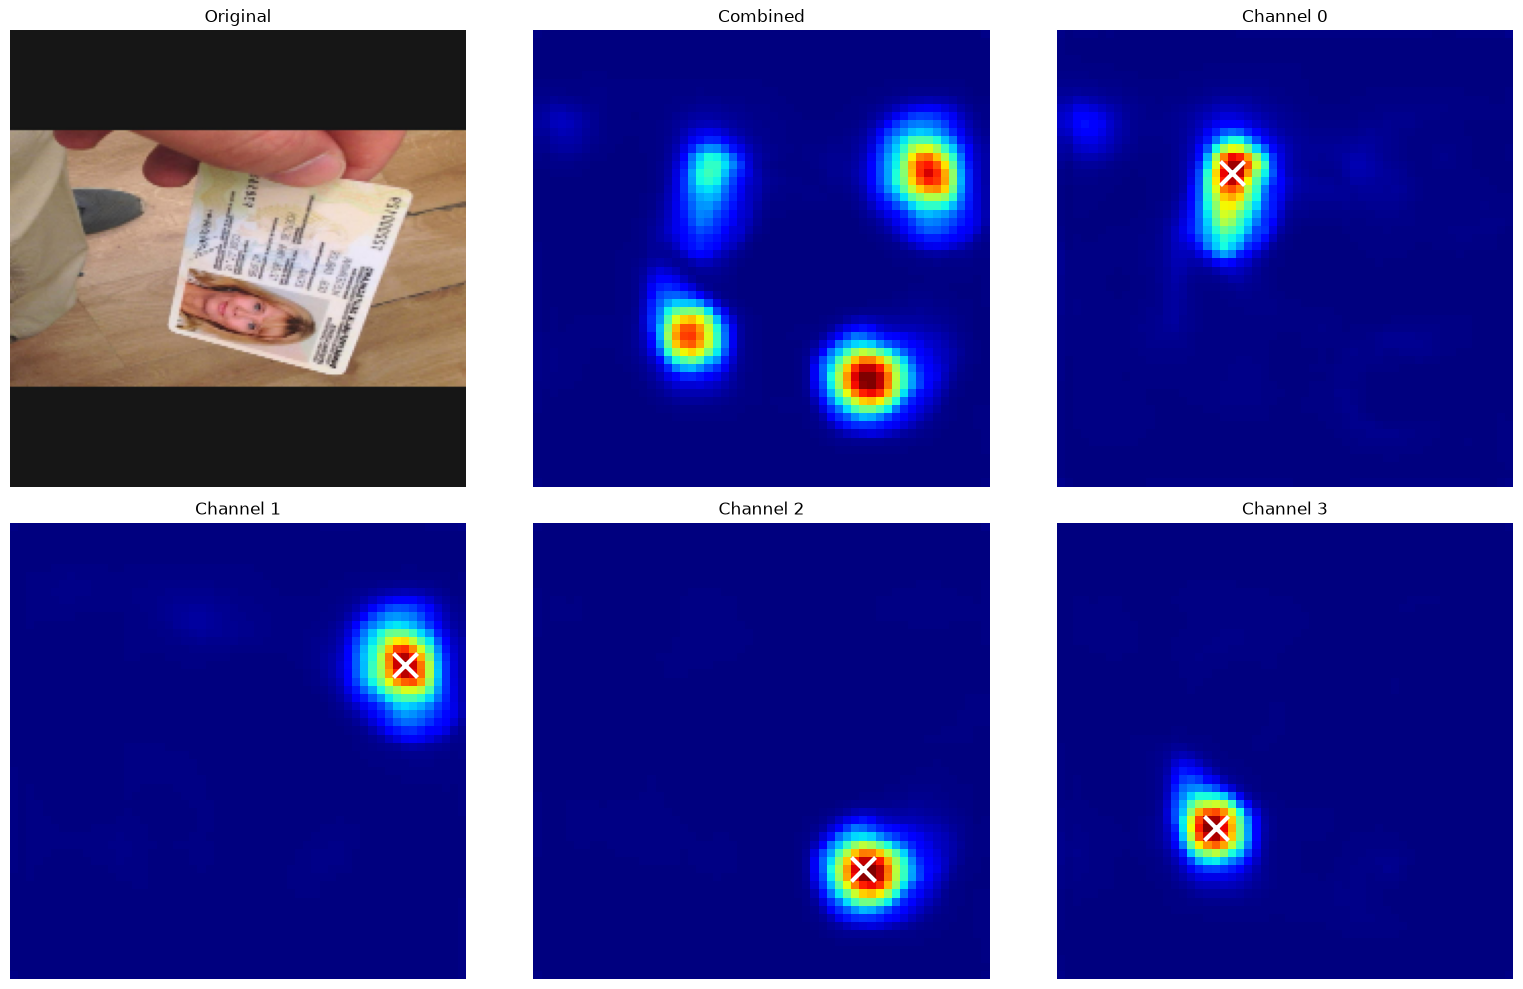

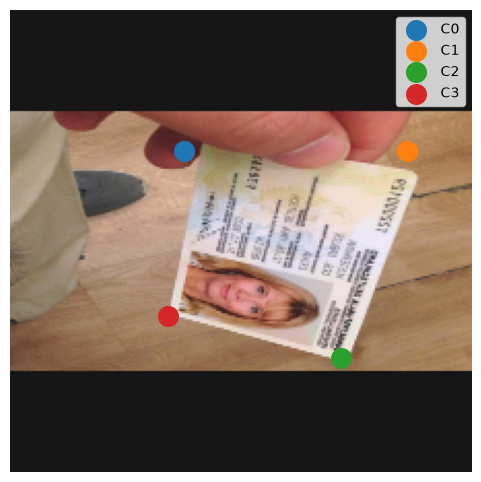

Channel 0: peak=(28,9) value=0.740052
Channel 1: peak=(52,20) value=0.917643
Channel 2: peak=(31,46) value=0.809362
Channel 3: peak=(7,38) value=0.307614


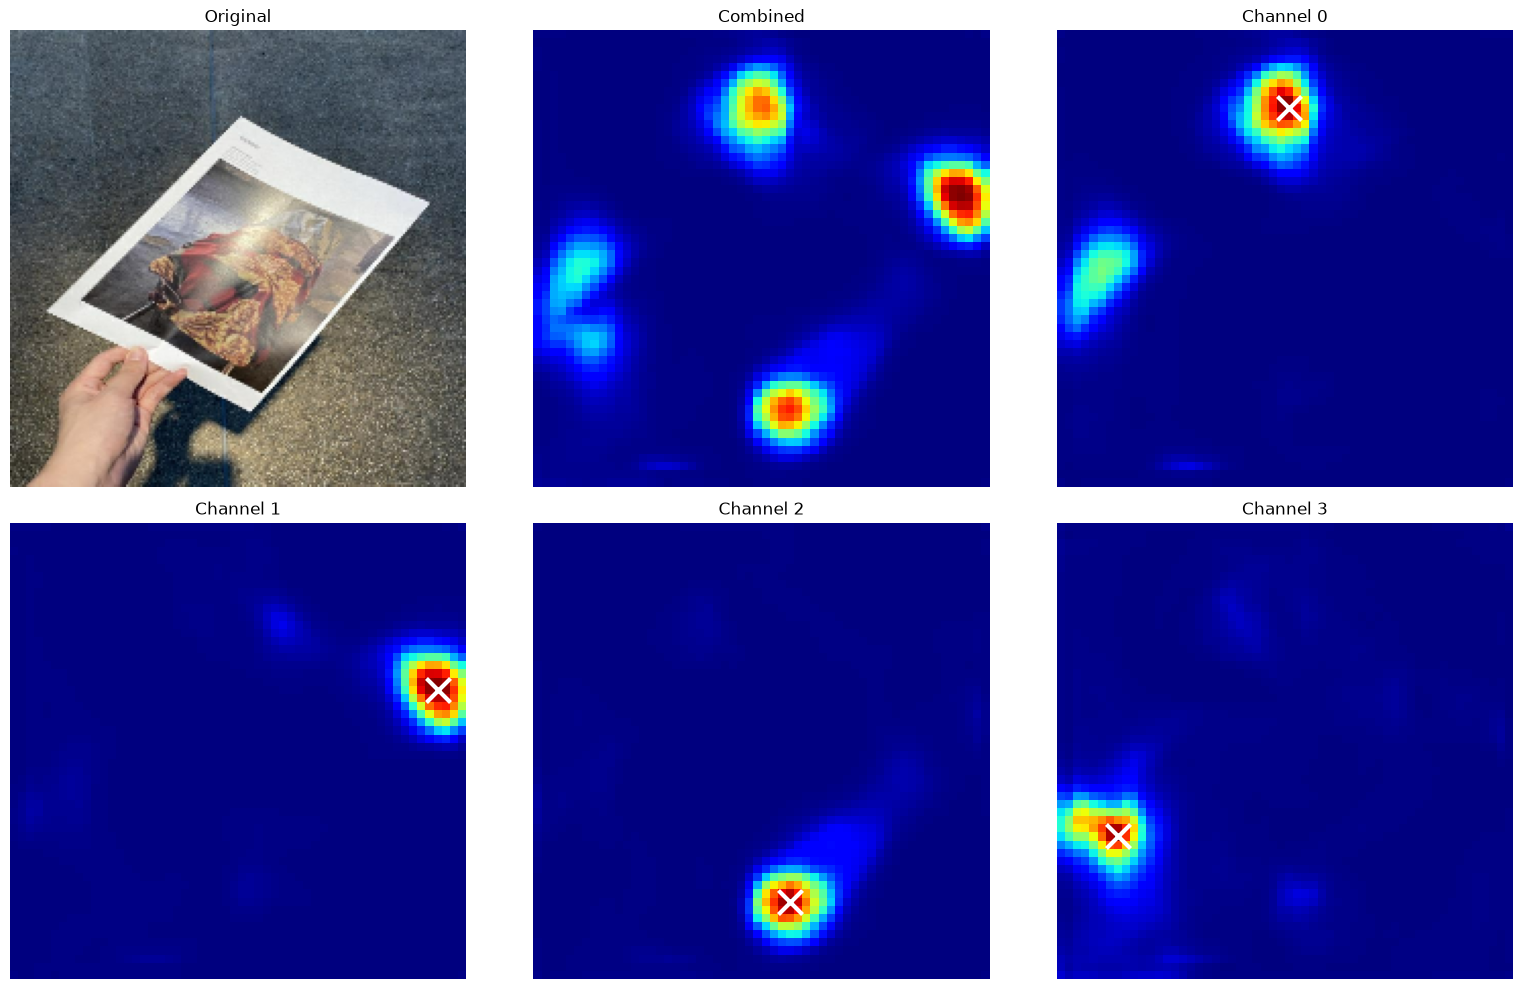

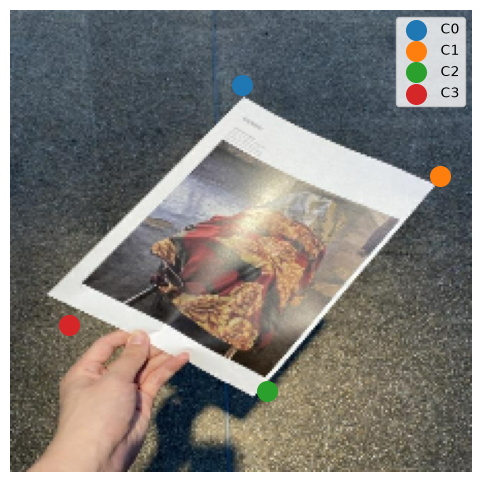

Channel 0: peak=(17,2) value=0.374169
Channel 1: peak=(31,2) value=0.827698
Channel 2: peak=(37,53) value=0.655544
Channel 3: peak=(20,53) value=0.641057


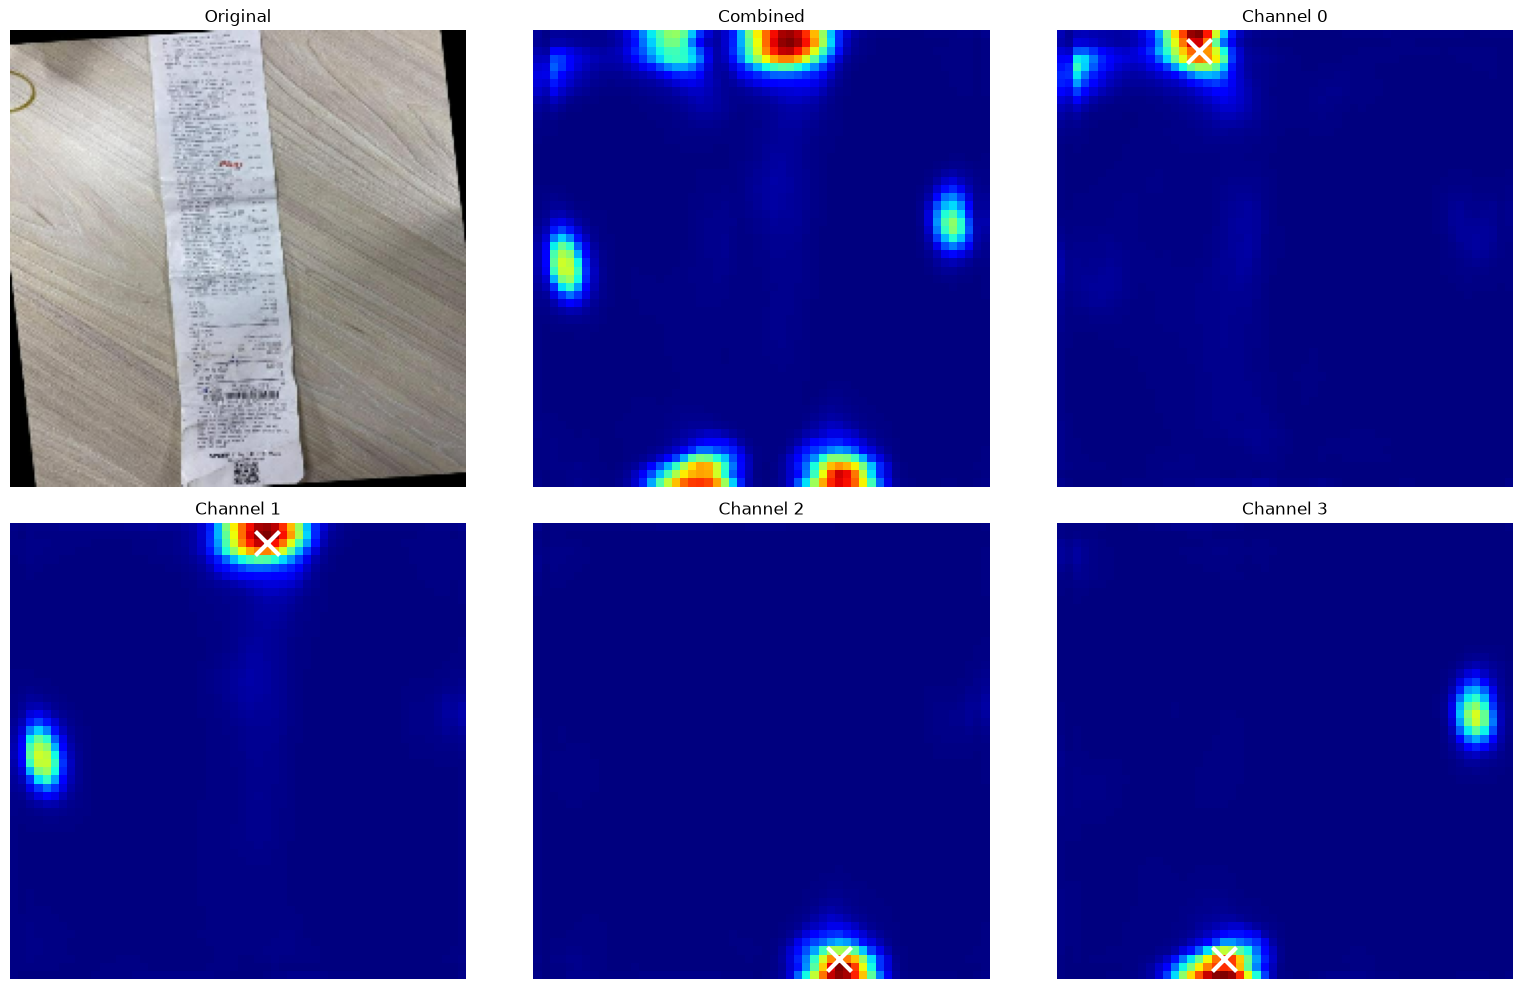

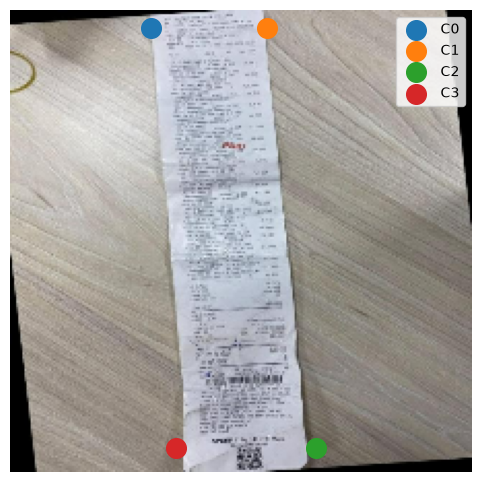

Channel 0: peak=(8,18) value=0.935234
Channel 1: peak=(52,21) value=0.895146
Channel 2: peak=(46,39) value=0.928777
Channel 3: peak=(4,35) value=0.907067


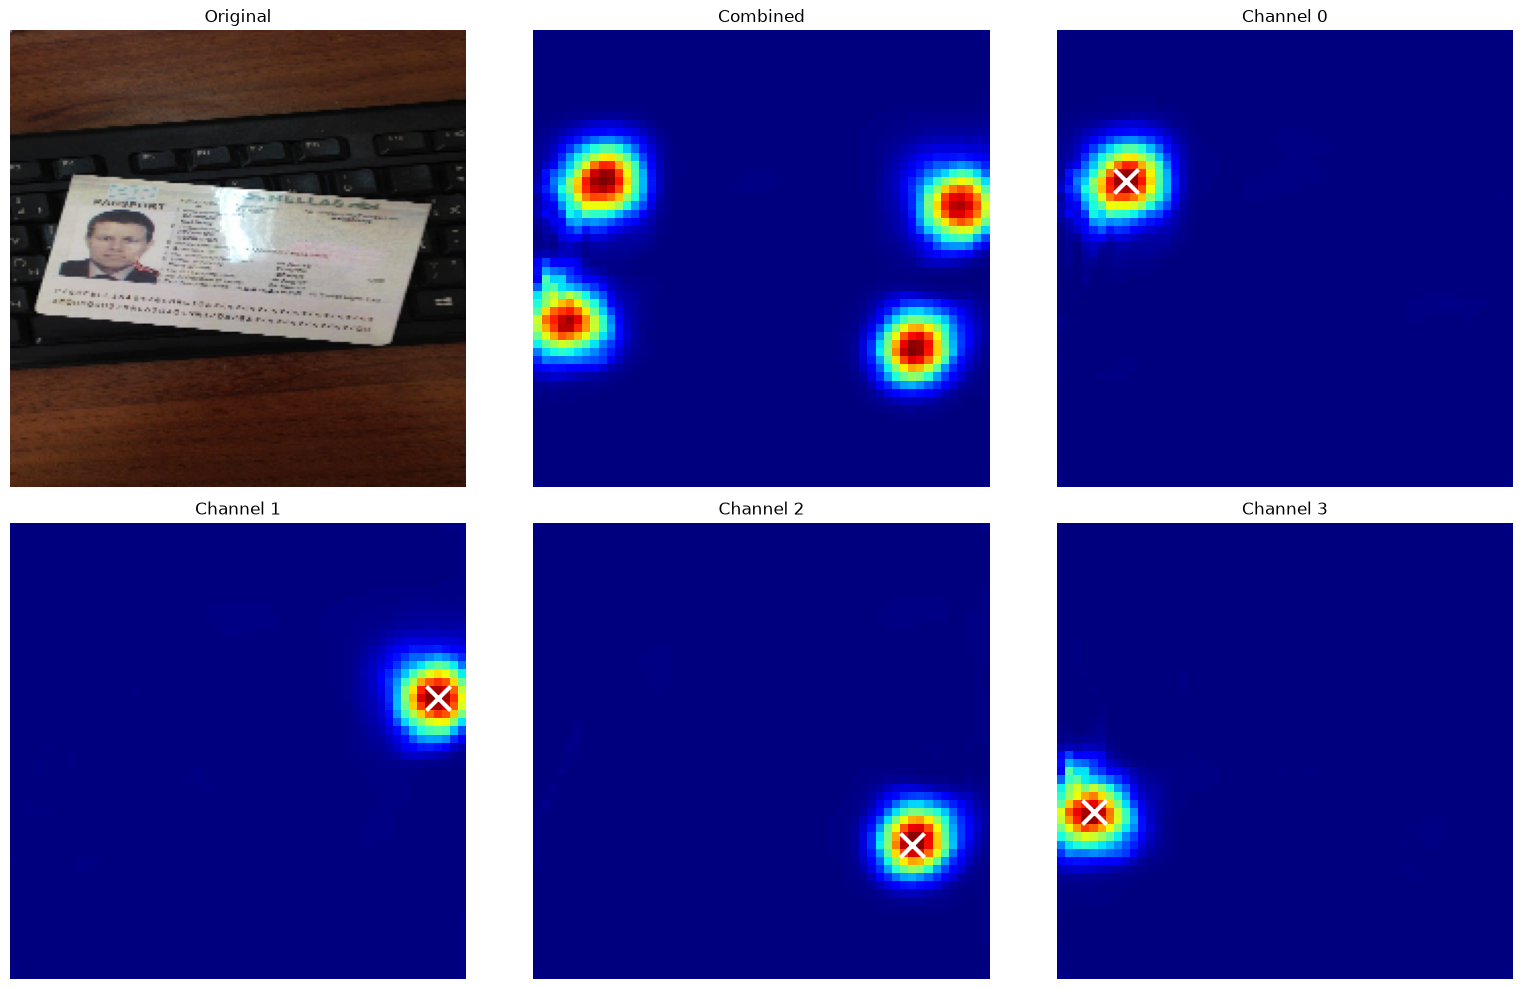

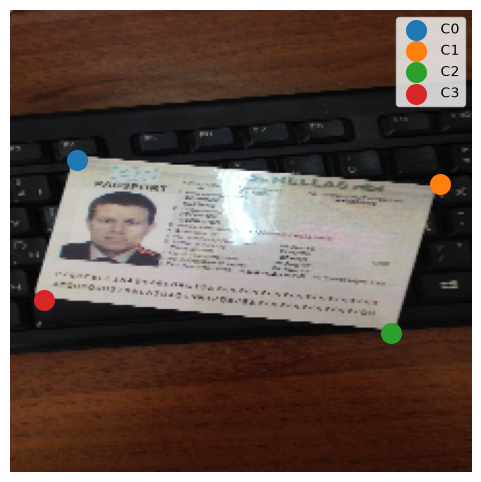

Channel 0: peak=(2,16) value=0.693348
Channel 1: peak=(53,20) value=0.698088
Channel 2: peak=(53,38) value=0.774873
Channel 3: peak=(2,35) value=0.740316


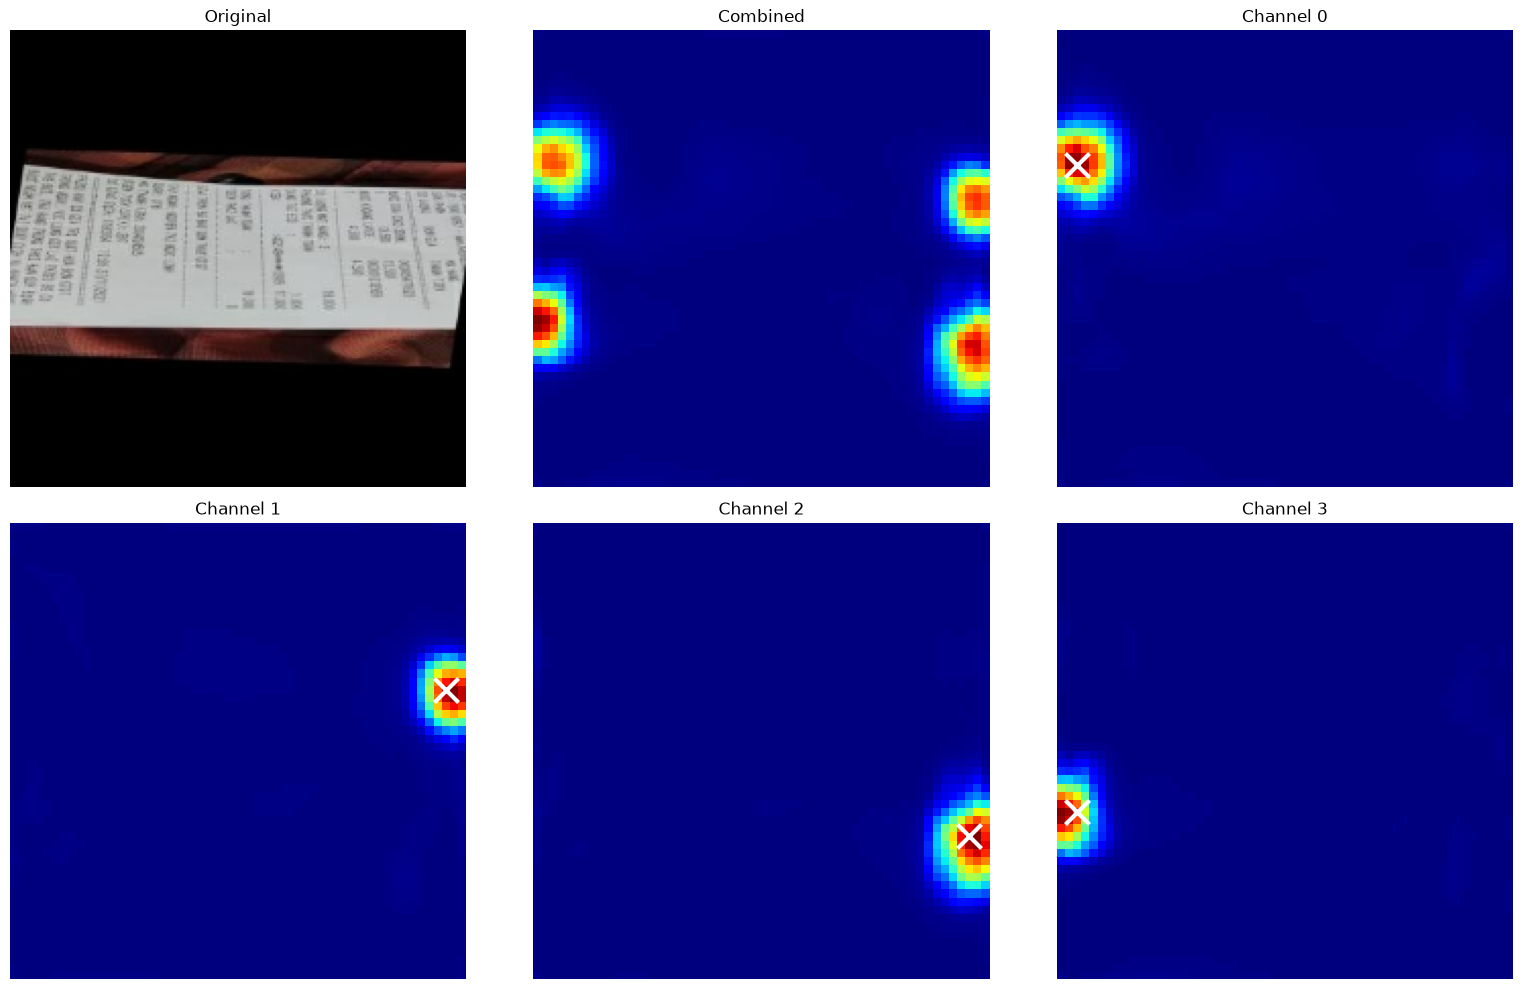

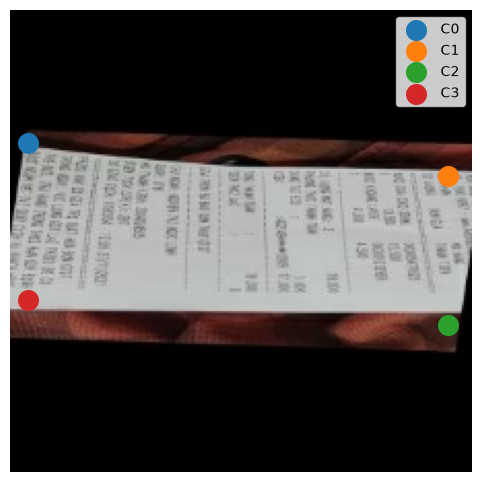

Channel 0: peak=(2,11) value=0.684294
Channel 1: peak=(44,2) value=0.749538
Channel 2: peak=(53,41) value=0.907990
Channel 3: peak=(7,52) value=0.770370


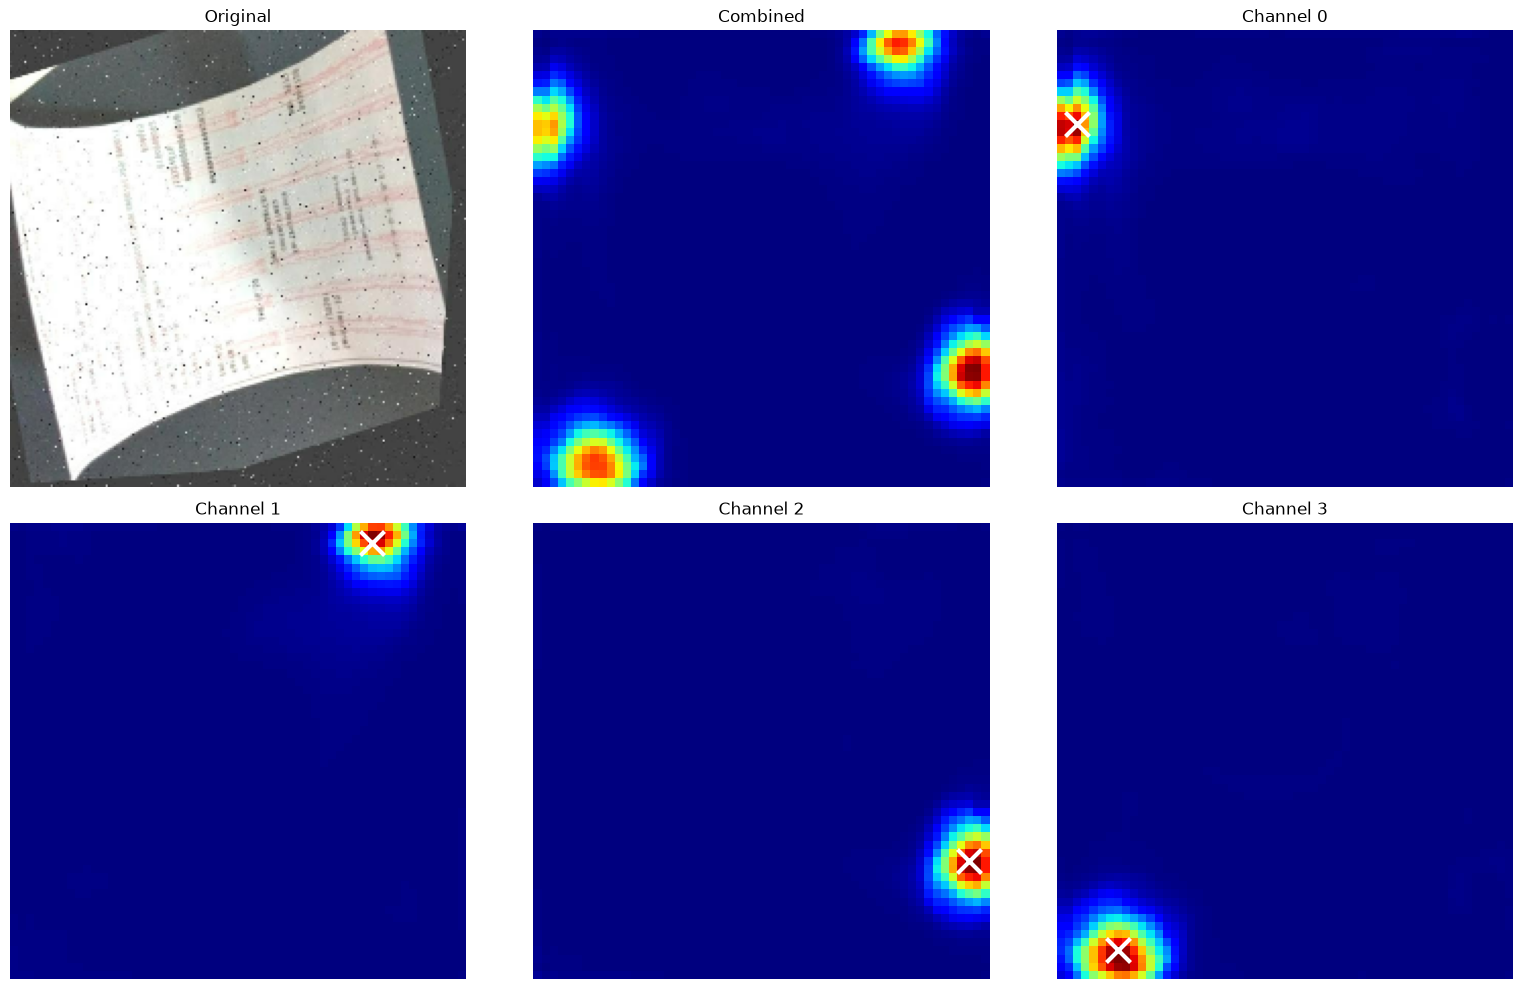

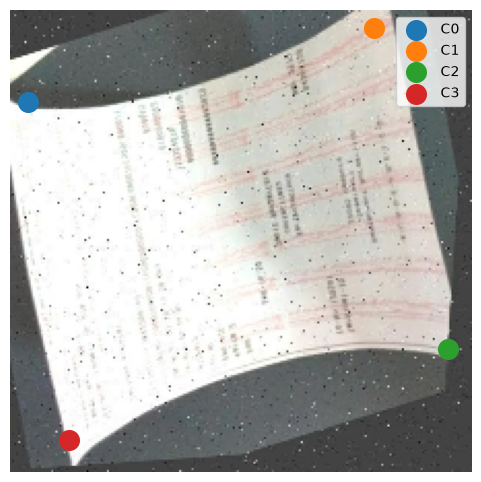

Channel 0: peak=(12,24) value=0.874321
Channel 1: peak=(43,25) value=0.904288
Channel 2: peak=(45,40) value=0.728622
Channel 3: peak=(11,41) value=0.701232


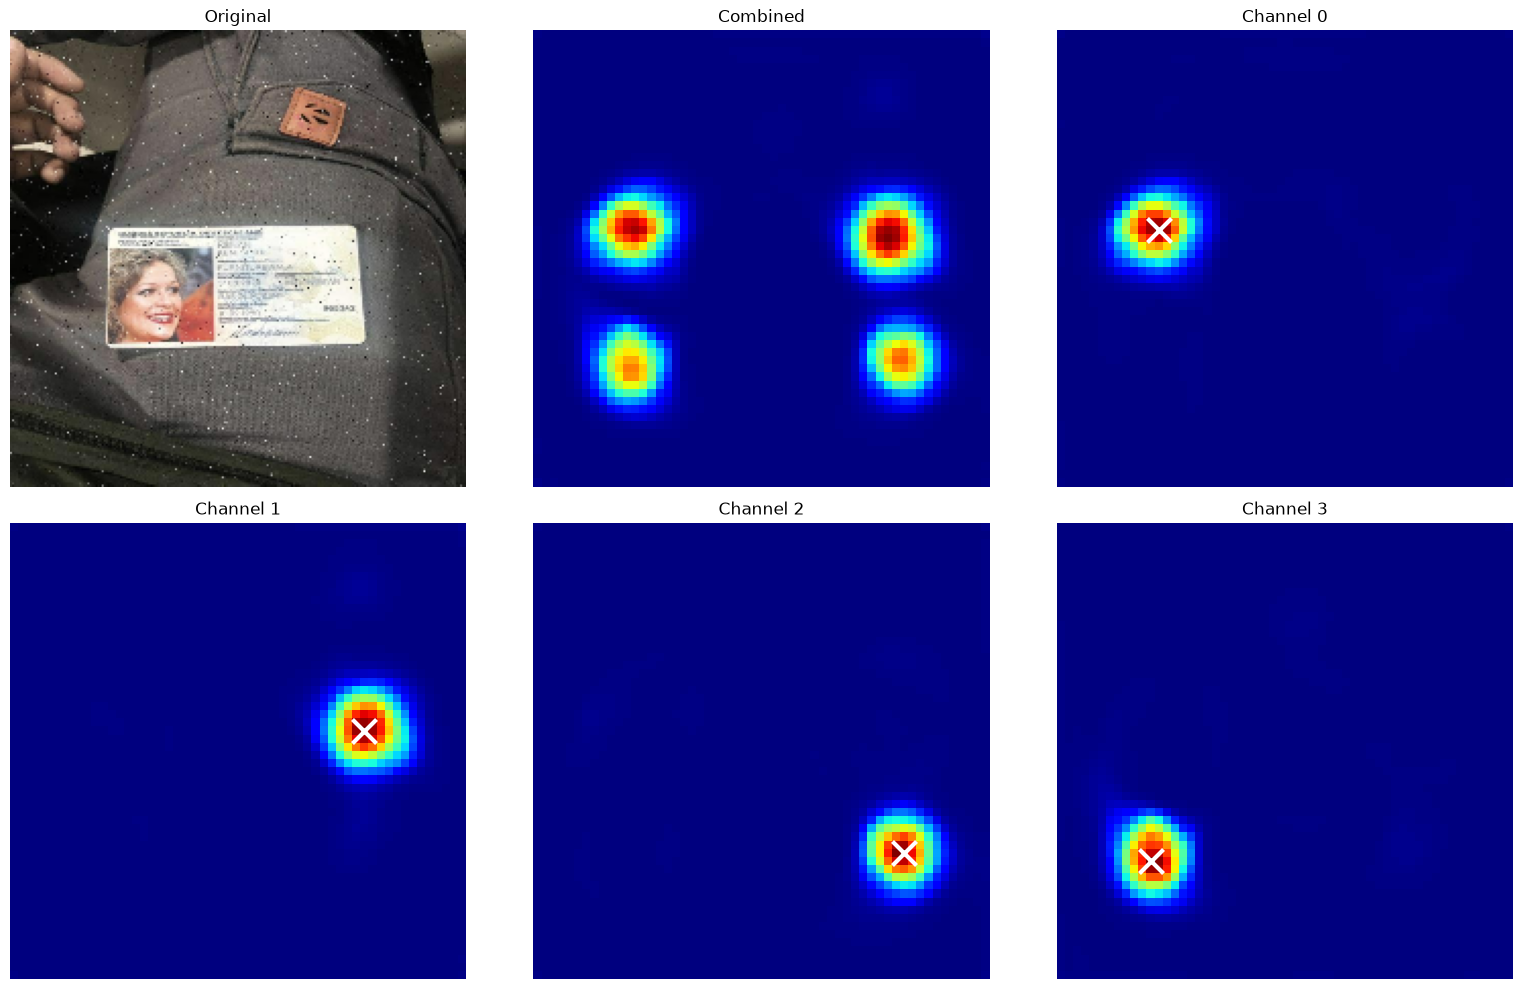

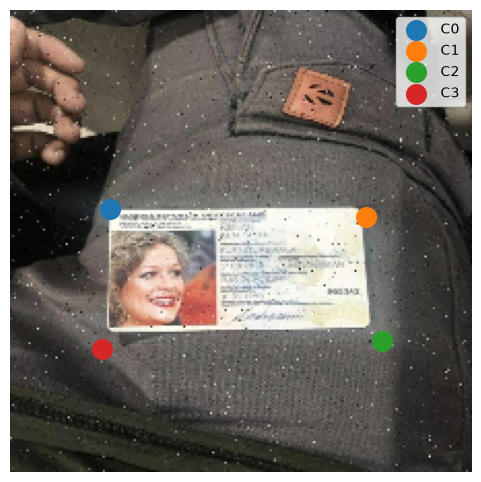

Channel 0: peak=(3,2) value=0.933357
Channel 1: peak=(53,2) value=0.956370
Channel 2: peak=(53,53) value=0.845821
Channel 3: peak=(2,53) value=0.891182


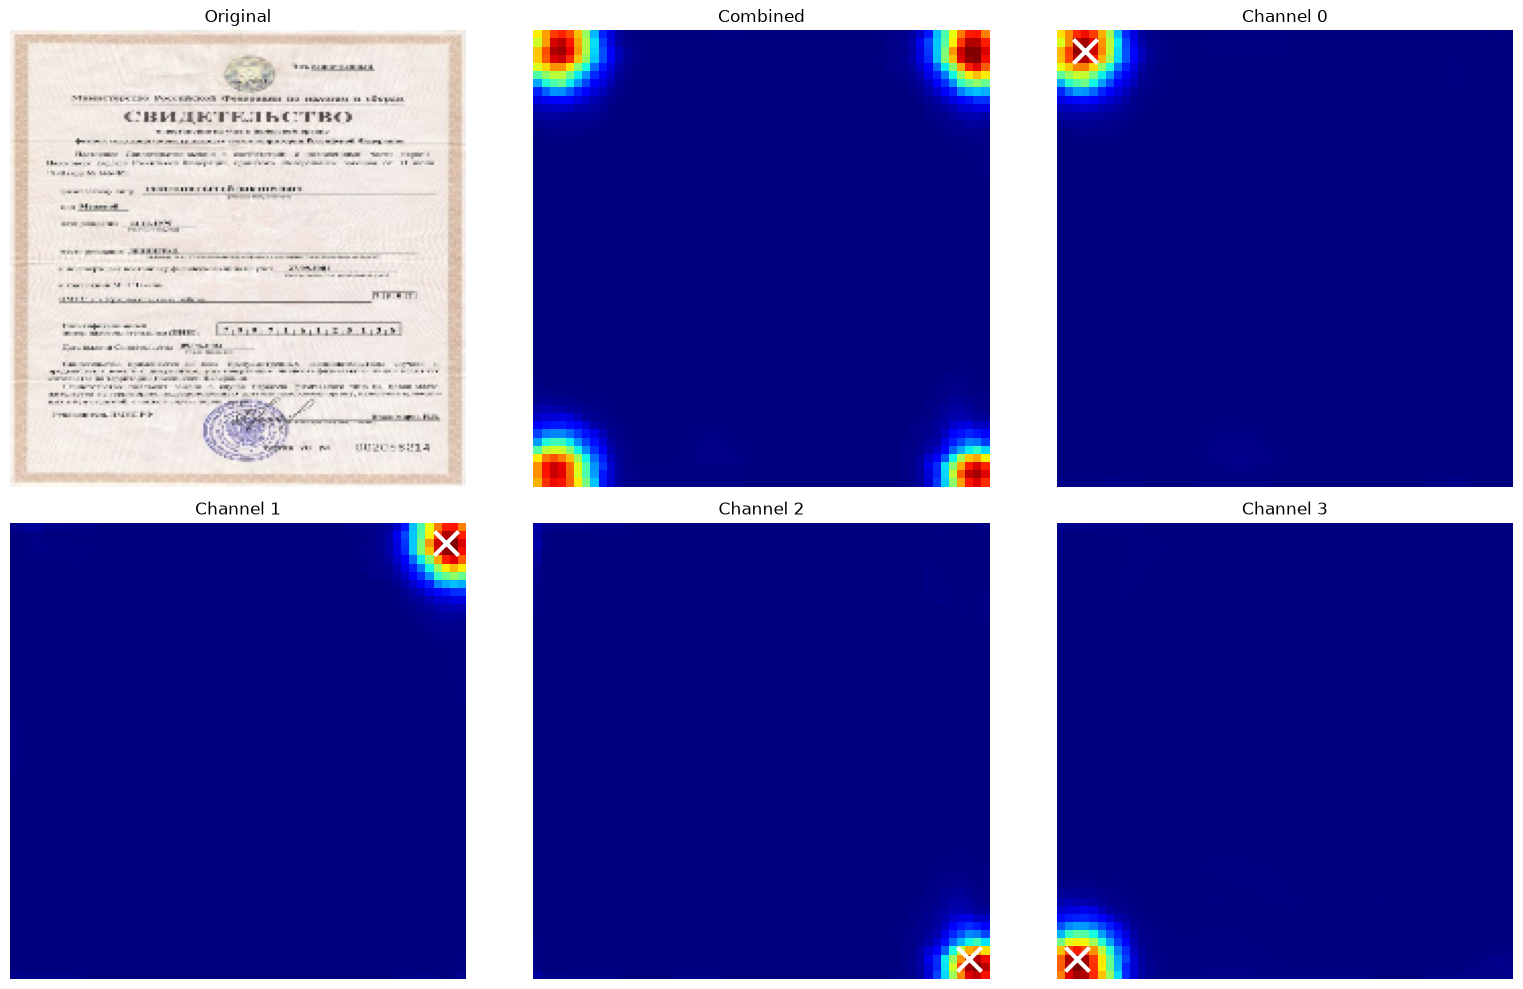

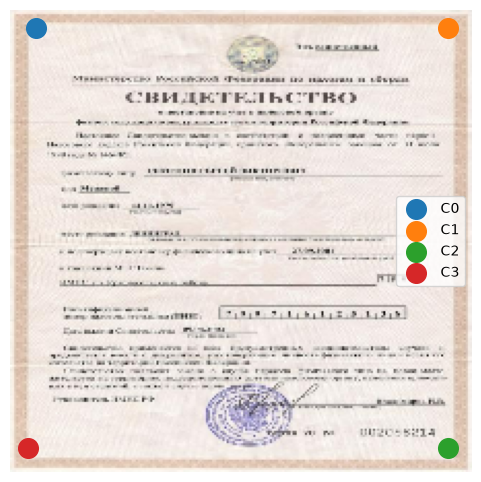

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def find_peak_ignore_border(hm, border=2):
    hm = hm.copy()

    hm[:border, :] = -1
    hm[-border:, :] = -1
    hm[:, :border] = -1
    hm[:, -border:] = -1

    y, x = np.unravel_index(np.argmax(hm), hm.shape)

    return x, y


def visualize_peaks(model, tf_dataset, num_samples=8):

    sample_pool = max(num_samples * 8, 64)
    sampled_ds = tf_dataset.unbatch().shuffle(sample_pool).batch(num_samples)

    for batch_images, (batch_heatmaps, batch_doc_present) in sampled_ds.take(1):
        break

    pred_heatmaps, pred_presence = model.predict(
        batch_images[:num_samples],
        verbose=0
    )

    for sample_idx in range(num_samples):

        image = batch_images[sample_idx].numpy()
        p_heatmaps = pred_heatmaps[sample_idx]

        fig, axes = plt.subplots(
            2,
            3,
            figsize=(16, 10)
        )

        axes = axes.flatten()

        # Original image
        axes[0].imshow(image)
        axes[0].set_title("Original")
        axes[0].axis("off")

        # Combined heatmap
        combined = np.max(p_heatmaps, axis=-1)

        axes[1].imshow(combined, cmap="jet")
        axes[1].set_title("Combined")
        axes[1].axis("off")

        peak_points = []

        for ch in range(4):

            hm = p_heatmaps[:, :, ch]

            x, y = find_peak_ignore_border(
                hm,
                border=2
            )

            peak_points.append([x, y])

            print(
                f"Channel {ch}: "
                f"peak=({x},{y}) "
                f"value={hm[y,x]:.6f}"
            )

            if ch < 4:

                ax = axes[ch + 2]

                ax.imshow(
                    hm,
                    cmap="jet"
                )

                ax.scatter(
                    x,
                    y,
                    c="white",
                    marker="x",
                    s=300,
                    linewidths=3
                )

                ax.set_title(
                    f"Channel {ch}"
                )

                ax.axis("off")

        plt.tight_layout()
        plt.show()

        # Draw all peaks on original image
        fig, ax = plt.subplots(figsize=(6, 6))

        ax.imshow(image)

        for ch, (x, y) in enumerate(peak_points):

            x_img = x * image.shape[1] / 56
            y_img = y * image.shape[0] / 56

            ax.scatter(
                x_img,
                y_img,
                s=200,
                label=f"C{ch}"
            )

        ax.legend()
        ax.axis("off")
        plt.show()


visualize_peaks(
    model,
    test_ds,
    num_samples=8
)